# Tugas #4: Data-Centric Improvement and Model Interpretation

Notebook ini melanjutkan pipeline terbaik Tugas #3. Model dan preprocessing **tidak diubah**:
yang diubah hanya data train (imbalance treatment, review label Cleanlab), supaya selisih
performa bisa diatributkan ke perubahan data.

Setup yang dipertahankan dari Tugas #3:
- Split raw 70/30 stratified (`random_state=42`). Semua CV hanya di data train.
- `StratifiedKFold(5, shuffle=True, random_state=42)`, fold identik di semua eksperimen.
- Primary metric: **MCC**. Macro F1 ditambahkan sebagai kolom pendamping.
- Test set baru dipakai sekali di evaluasi akhir.

In [1]:
import sys, os, warnings
sys.path.append('../src')
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd

from data_utils import load_data
from preprocessing import split_raw
from models import get_models
from pipeline_experiments import build_pipeline, CHI2_K
from data_centric import cv_evaluate, get_cv, PRIMARY_METRIC

pd.set_option('display.width', 140)
TABLE_DIR, FIG_DIR = '../results/tables', '../results/figures'
os.makedirs(TABLE_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

df = load_data()
X_train_raw, X_test_raw, y_train, y_test = split_raw(df)
X, y = X_train_raw, y_train   # alias: semua CV di bawah HANYA memakai data train

print('Train:', X_train_raw.shape, '| proporsi positif:', round(y_train.mean(), 4))
print('Test :', X_test_raw.shape, '| proporsi positif:', round(y_test.mean(), 4), '(tidak disentuh)')

Train: (8631, 17) | proporsi positif: 0.1548
Test : (3699, 17) | proporsi positif: 0.1546 (tidak disentuh)


## 1. Baseline (D0)

D0 adalah pipeline terbaik Tugas #3 apa adanya: `CorrectedPreprocessor` (one-hot `Month` dan
`VisitorType`, chi-square top-20, standard scaling) lalu SMOTE 1:1 di dalam pipeline, lalu
XGBoost `max_depth=2`. Di Tugas #3 pipeline ini tetap yang terbaik di test set (MCC 0,5955),
mengalahkan versi log-transform/pruning dan versi tuned.

Sebagai sanity check, MCC CV harus sama dengan Tugas #3 (0,6257).

In [2]:
xgb = get_models()['XGBoost']
pipe_d0 = build_pipeline(xgb, k=CHI2_K, drop_features=None, log_transform=False, use_smote=True)

summary_d0, folds_d0 = cv_evaluate(pipe_d0, X, y)
print('D0 (baseline Tugas #3), 5-fold CV di data train:')
print(summary_d0)

T3_MCC = 0.6257
assert abs(summary_d0.loc['MCC', 'Mean'] - T3_MCC) < 1e-4, 'Baseline tidak cocok dengan Tugas #3'
print(f'\nSanity check OK: MCC = {summary_d0.loc["MCC", "Mean"]:.4f} (Tugas #3: {T3_MCC})')

D0 (baseline Tugas #3), 5-fold CV di data train:
                        Mean     Std
Accuracy              0.8940  0.0069
Precision             0.6343  0.0217
TPR (Recall)          0.7470  0.0276
F1-Score              0.6857  0.0190
TNR                   0.9209  0.0075
MCC                   0.6257  0.0228
auROC                 0.9265  0.0076
auPR                  0.7307  0.0233
Precision (weighted)  0.9029  0.0060
F1-Score (weighted)   0.8974  0.0064
Macro F1              0.8110  0.0115

Sanity check OK: MCC = 0.6257 (Tugas #3: 0.6257)


In [3]:
print('Skor per fold D0:')
print(folds_d0[['MCC', 'Macro F1', 'F1-Score', 'TPR (Recall)', 'Precision', 'auPR']].round(4))

summary_d0.to_csv(f'{TABLE_DIR}/tugas4_d0_baseline_cv.csv')
folds_d0.round(4).to_csv(f'{TABLE_DIR}/tugas4_d0_baseline_folds.csv')

Skor per fold D0:
           MCC  Macro F1  F1-Score  TPR (Recall)  Precision    auPR
Fold 1  0.6147    0.8055    0.6769        0.7388     0.6246  0.7032
Fold 2  0.6707    0.8338    0.7232        0.7828     0.6720  0.7601
Fold 3  0.6165    0.8048    0.6777        0.7640     0.6090  0.7479
Fold 4  0.6191    0.8073    0.6803        0.7491     0.6231  0.7390
Fold 5  0.6076    0.8033    0.6703        0.7004     0.6426  0.7035


Baseline cocok dengan Tugas #3, jadi fold dan pipeline terbukti identik. Std MCC
antar fold sekitar 0,02: selisih antar eksperimen data di bawah ukuran ini perlu dibaca sebagai
noise, bukan perbaikan.

## 2. Identifikasi Masalah Kualitas Data

EDA lengkap tidak diulang. Bagian ini mengambil temuan Tugas #2/#3 yang belum dituntaskan,
lalu menambah beberapa pengecekan yang belum pernah dilakukan. Semua pengecekan hanya di data train.

In [4]:
d = X.copy(); d['Revenue'] = y.values
feat = list(X.columns)

# (a) Class imbalance
print('(a) Distribusi kelas train:', y.value_counts().to_dict(), f'| positif = {y.mean():.2%}')

# (b) Duplikat: apakah ada pasangan fitur identik dengan label berbeda?
dup_mask = d.duplicated(subset=feat, keep=False)
grp = d[dup_mask].groupby(feat, dropna=False)['Revenue'].nunique()
print(f'(b) Baris dalam grup duplikat: {dup_mask.sum()} ({d.duplicated(subset=feat).sum()} salinan ekstra), '
      f'{len(grp)} grup, grup dengan label konflik: {(grp > 1).sum()}, '
      f'proporsi Revenue=1 di duplikat: {d[dup_mask].Revenue.mean():.2%}')
print('    Profil median duplikat:',
      d[dup_mask][['ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues']]
      .median().to_dict())

(a) Distribusi kelas train: {0: 7295, 1: 1336} | positif = 15.48%
(b) Baris dalam grup duplikat: 126 (74 salinan ekstra), 52 grup, grup dengan label konflik: 0, proporsi Revenue=1 di duplikat: 0.00%
    Profil median duplikat: {'ProductRelated': 1.0, 'ProductRelated_Duration': 0.0, 'BounceRates': 0.2, 'ExitRates': 0.2, 'PageValues': 0.0}


In [5]:
# (c) Nilai inkonsisten: jumlah halaman > 0 tetapi durasi = 0 (dan kebalikannya)
rows = []
for cnt, dur in [('Administrative', 'Administrative_Duration'),
                 ('Informational', 'Informational_Duration'),
                 ('ProductRelated', 'ProductRelated_Duration')]:
    m = (d[cnt] > 0) & (d[dur] == 0)
    rows.append({'pasangan': f'{cnt} > 0, {dur} = 0', 'n': int(m.sum()),
                 'Revenue=1 (%)': round(100 * d[m].Revenue.mean(), 2)})
    rows.append({'pasangan': f'{cnt} = 0, {dur} > 0', 'n': int(((d[cnt] == 0) & (d[dur] > 0)).sum()),
                 'Revenue=1 (%)': None})
rows.append({'pasangan': 'Durasi negatif (semua kolom durasi)',
             'n': int((d[[c for c in feat if c.endswith('_Duration')]] < 0).any(axis=1).sum()),
             'Revenue=1 (%)': None})
rows.append({'pasangan': 'BounceRates > ExitRates', 'n': int((d.BounceRates > d.ExitRates).sum()),
             'Revenue=1 (%)': round(100 * d[d.BounceRates > d.ExitRates].Revenue.mean(), 2)})
print('(c) Pengecekan konsistensi:')
print(pd.DataFrame(rows).to_string(index=False))

# (d) Segmen anomali: sesi "bounce murni" (BounceRates = ExitRates = 0,2, nilai maksimum)
bb = (d.BounceRates == 0.2) & (d.ExitRates == 0.2)
td = d[[c for c in feat if c.endswith('_Duration')]].sum(axis=1)
print(f'\n(d) Sesi BounceRates=ExitRates=0,2: {bb.sum()} baris, Revenue=1: {d[bb].Revenue.sum()} '
      f'| sesi total durasi = 0: {(td == 0).sum()} baris, Revenue=1: {d[td == 0].Revenue.sum()}')
print('    Sesi bounce murni tapi Revenue=1 (kandidat label mencurigakan, dibawa ke Cleanlab):')
print(d[bb & (d.Revenue == 1)][['ProductRelated', 'ProductRelated_Duration', 'PageValues',
                                'Month', 'VisitorType', 'TrafficType']])

(c) Pengecekan konsistensi:
                                       pasangan   n  Revenue=1 (%)
Administrative > 0, Administrative_Duration = 0  82          24.39
Administrative = 0, Administrative_Duration > 0   0            NaN
  Informational > 0, Informational_Duration = 0 160          21.25
  Informational = 0, Informational_Duration > 0   0            NaN
ProductRelated > 0, ProductRelated_Duration = 0 509           1.18
ProductRelated = 0, ProductRelated_Duration > 0   0            NaN
            Durasi negatif (semua kolom durasi)   0            NaN
                        BounceRates > ExitRates 132          10.61

(d) Sesi BounceRates=ExitRates=0,2: 492 baris, Revenue=1: 2 | sesi total durasi = 0: 507 baris, Revenue=1: 2
    Sesi bounce murni tapi Revenue=1 (kandidat label mencurigakan, dibawa ke Cleanlab):
      ProductRelated  ProductRelated_Duration  PageValues Month        VisitorType  TrafficType
2524               3                      0.0         0.0   Nov  Returning_

In [6]:
# (e) PageValues: fitur paling dominan di EDA, sekaligus kandidat leakage-adjacent
pv = d.PageValues > 0
print(f'(e) PageValues > 0: {pv.sum()} sesi, Revenue=1 rate {d[pv].Revenue.mean():.2%} '
      f'| PageValues = 0: Revenue=1 rate {d[~pv].Revenue.mean():.2%}')
print(f'    Revenue=1 dengan PageValues = 0: {((~pv) & (d.Revenue == 1)).sum()} dari {d.Revenue.sum()} '
      f'({((~pv) & (d.Revenue == 1)).sum() / d.Revenue.sum():.1%})')

# (f) Level kategori langka (segmen bermasalah untuk one-hot / generalisasi)
for c in ['Browser', 'OperatingSystems', 'TrafficType', 'VisitorType']:
    vc = d[c].value_counts()
    print(f'(f) {c}: {(vc < 30).sum()} level dengan < 30 baris (total {vc[vc < 30].sum()} baris)')
print('    Month di train (Jan dan Apr tidak ada di dataset):', d.Month.value_counts().to_dict())

(e) PageValues > 0: 1911 sesi, Revenue=1 rate 57.04% | PageValues = 0: Revenue=1 rate 3.66%
    Revenue=1 dengan PageValues = 0: 246 dari 1336 (18.4%)
(f) Browser: 3 level dengan < 30 baris (total 13 baris)
(f) OperatingSystems: 3 level dengan < 30 baris (total 23 baris)
(f) TrafficType: 7 level dengan < 30 baris (total 63 baris)
(f) VisitorType: 0 level dengan < 30 baris (total 0 baris)
    Month di train (Jan dan Apr tidak ada di dataset): {'May': 2377, 'Nov': 2066, 'Mar': 1351, 'Dec': 1208, 'Oct': 381, 'Sep': 319, 'Aug': 308, 'Jul': 299, 'June': 189, 'Feb': 133}


### Ringkasan masalah dan tindakan

| # | Masalah | Bukti (data train) | Status di Tugas #2/#3 | Tindakan Tugas #4 |
|---|---|---|---|---|
| a | Class imbalance | Positif 15,48% (1.336 dari 8.631) | Ditangani dengan SMOTE 1:1, tidak pernah dibandingkan dengan alternatif | **Step 3**: bandingkan tanpa treatment, `scale_pos_weight`, SMOTE |
| b | Duplikat | 126 baris dalam 52 grup (74 salinan ekstra). Semua Revenue=0, tanpa label konflik. Profilnya sesi bounce 1 halaman, durasi 0 | Dicatat di EDA, tidak ditangani | **Tidak dihapus** (dilarang brief, dan wajar: sesi bounce identik memang bisa terjadi dari user berbeda). Efeknya ke CV dicek di Step 7 |
| c | Durasi 0 padahal jumlah halaman > 0 | 509 sesi (ProductRelated), 160 (Informational), 82 (Administrative). Tidak ada kebalikannya, tidak ada nilai negatif | Belum dicek | Konsisten dengan cara Google Analytics menghitung durasi (halaman terakhir sesi tidak punya durasi), jadi bukan error. **Tidak dikoreksi** |
| d | Sesi bounce murni dengan Revenue=1 | 492 sesi BounceRates=ExitRates=0,2, hanya 2 yang Revenue=1 (tanpa durasi, PageValues 0) | Belum dicek | Kandidat label mencurigakan, **dibawa ke Step 4 (Cleanlab)** |
| e | PageValues sangat dominan | Rate pembelian 57% jika > 0, 3,7% jika = 0. Korelasi 0,49 dengan target | Dipakai apa adanya | Definisinya dihitung dari halaman yang dikunjungi *sebelum transaksi*, jadi berpotensi leakage-adjacent. **Diinvestigasi di Step 6/7** dengan SHAP |
| f | Level kategori langka | TrafficType 7 level < 30 baris, Browser 3, OS 3, VisitorType 'Other' 67 | One-hot hanya untuk Month/VisitorType, kode lain dipakai sebagai angka | Dicatat sebagai segmen berisiko, dicek lagi kalau muncul di misklasifikasi |
| g | Penulisan kategori tidak seragam | `Month` memakai 'June' (4 huruf) sementara bulan lain 3 huruf ('Jul', 'Aug') | Belum dicek | Kosmetik saja: one-hot memperlakukannya sebagai satu level yang konsisten. **Tidak diubah** |

Missing value tidak ada (sudah diverifikasi di Tugas #2), jadi tidak dibahas ulang. Outlier IQR
(misalnya `ProductRelated_Duration`) sudah dibahas di Tugas #2/#3 dan tidak relevan untuk model
pohon, jadi tidak diinvestigasi ulang.

In [7]:
# Hitungan deskriptif (bukan dasar keputusan): sesi bounce murni + Revenue=1 di seluruh dataset.
# Test set hanya dihitung, tidak diubah dan tidak dipakai untuk memilih intervensi.
dur_cols = [c for c in feat if c.endswith('_Duration')]
rows = []
for part, Xp, yp in [('Train', X_train_raw, y_train), ('Test', X_test_raw, y_test)]:
    bb_p = (Xp.BounceRates == 0.2) & (Xp.ExitRates == 0.2)
    z_p = Xp[dur_cols].sum(axis=1) == 0
    rows.append({'Bagian': part, 'Sesi': len(Xp), 'Bounce murni': int(bb_p.sum()),
                 'Bounce murni & Revenue=1': int((bb_p & (yp == 1)).sum()),
                 'Durasi total 0 & Revenue=1': int((z_p & (yp == 1)).sum()),
                 'idx': list(Xp.index[bb_p & (yp == 1)])})
bounce_all = pd.DataFrame(rows)
bounce_all.loc[len(bounce_all)] = ['Total', bounce_all.Sesi.sum(), bounce_all['Bounce murni'].sum(),
                                   bounce_all['Bounce murni & Revenue=1'].sum(), bounce_all['Durasi total 0 & Revenue=1'].sum(), '-']
bounce_all.to_csv(f'{TABLE_DIR}/tugas4_bounce_buyers_all.csv', index=False)
print('Pola yang sama juga muncul 1 kali di test (idx 264). Record test tidak diubah sesuai brief.')
bounce_all

Pola yang sama juga muncul 1 kali di test (idx 264). Record test tidak diubah sesuai brief.


,Bagian,Sesi,Bounce murni,Bounce murni & Revenue=1,Durasi total 0 & Revenue=1,idx
0,Train,8631,492,2,2,"[2524, 3482]"
1,Test,3699,208,1,1,[264]
2,Total,12330,700,3,3,-


In [8]:
# Simpan tabel masalah kualitas data (termasuk yang TIDAK diubah) untuk laporan
issues = pd.DataFrame([
    ['a', 'Class imbalance', 'Positif 15,48% (1.336 dari 8.631)', 'Ditindaklanjuti', 'Step 3: none vs scale_pos_weight vs SMOTE'],
    ['b', 'Duplikat', '126 baris, 52 grup, 74 salinan ekstra; semua Revenue=0, tanpa label konflik; profil sesi bounce 1 halaman',
     'Tidak diubah', 'Dilarang dihapus dan wajar (sesi bounce identik dari user berbeda); efek ke CV dicek di Step 7'],
    ['c', 'Durasi 0 padahal jumlah halaman > 0', 'ProductRelated 509, Informational 160, Administrative 82; tidak ada kebalikan/negatif',
     'Tidak diubah', 'Konsisten dengan perhitungan durasi Google Analytics (halaman terakhir tanpa durasi)'],
    ['d', 'Sesi bounce murni dengan Revenue=1', '2 dari 492 sesi Bounce=Exit=0,2 (durasi 0, PageValues 0)',
     'Ditindaklanjuti', 'Kandidat label mencurigakan, diverifikasi di Step 4 (Cleanlab)'],
    ['e', 'PageValues sangat dominan', 'Rate beli 57,0% jika > 0 vs 3,7% jika = 0; korelasi 0,49',
     'Ditindaklanjuti', 'Potensi leakage-adjacent, diinvestigasi di Step 6/7 (SHAP)'],
    ['f', 'Level kategori langka', 'TrafficType 7 level < 30 baris (63), Browser 3 (13), OS 3 (23)',
     'Tidak diubah', 'Dicatat sebagai segmen berisiko, dicek bila muncul di misklasifikasi'],
    ['g', 'Penulisan kategori tidak seragam', "Month 'June' vs singkatan 3 huruf", 'Tidak diubah', 'Kosmetik, one-hot tetap konsisten'],
], columns=['id', 'masalah', 'bukti_train', 'status', 'tindakan'])
issues.to_csv(f'{TABLE_DIR}/tugas4_data_quality_issues.csv', index=False)
issues[['id', 'masalah', 'status']]

,id,masalah,status
0,a,Class imbalance,Ditindaklanjuti
1,b,Duplikat,Tidak diubah
2,c,Durasi 0 padahal jumlah halaman > 0,Tidak diubah
3,d,Sesi bounce murni dengan Revenue=1,Ditindaklanjuti
4,e,PageValues sangat dominan,Ditindaklanjuti
5,f,Level kategori langka,Tidak diubah
6,g,Penulisan kategori tidak seragam,Tidak diubah


## 3. Class Imbalance: Tanpa Treatment vs Class Weighting vs SMOTE

Tiga varian dibandingkan dengan preprocessing, model (XGBoost `max_depth=2`), dan fold yang sama:

- **I0, tanpa treatment**: pipeline D0 tanpa langkah SMOTE.
- **I1, class weighting**: XGBoost tidak punya `class_weight` (parameter itu diam-diam diabaikan),
  jadi padanannya `scale_pos_weight = n_negatif / n_positif`. Rasio dihitung dari data train;
  karena fold stratified, rasio di setiap fold train praktis sama (dicek di bawah).
- **I2, SMOTE 1:1** (= D0). SMOTE berada di dalam pipeline, jadi hanya diterapkan ke fold train.
  Fold validasi tetap pada distribusi asli.

Metrik yang dibaca: MCC (primary), Macro F1, F1/Precision/Recall kelas positif, dan auPR.
auPR tidak bergantung threshold, jadi dipakai untuk membedakan "model jadi lebih baik memisahkan kelas"
dari "threshold efektifnya hanya bergeser".

In [9]:
from data_centric import neg_pos_ratio, summary_row

spw = neg_pos_ratio(y)
fold_ratios = [neg_pos_ratio(y.iloc[tr]) for tr, _ in get_cv().split(X, y)]
print(f'scale_pos_weight (train): {spw:.4f} | per fold train: {[round(r, 4) for r in fold_ratios]}')

imb_pipes = {
    'I0 Tanpa treatment':        build_pipeline(xgb, use_smote=False),
    'I1 Class weighting (spw)':  build_pipeline(xgb, use_smote=False, use_class_weight=True, scale_pos_weight=spw),
    'I2 SMOTE 1:1 (= D0)':       build_pipeline(xgb, use_smote=True),
}
imb_summary, imb_folds = {}, {}
for name, pipe in imb_pipes.items():
    imb_summary[name], imb_folds[name] = cv_evaluate(pipe, X, y)

# Sanity check: I2 harus identik dengan D0
assert imb_summary['I2 SMOTE 1:1 (= D0)'].equals(summary_d0)

COLS = ['MCC', 'Macro F1', 'F1-Score', 'Precision', 'TPR (Recall)', 'TNR', 'auPR', 'auROC', 'Accuracy']
imb_table = pd.DataFrame([summary_row(s.loc[COLS], n) for n, s in imb_summary.items()])
imb_table.to_csv(f'{TABLE_DIR}/tugas4_imbalance_comparison.csv')
imb_table

scale_pos_weight (train): 5.4603 | per fold train: [5.4644, 5.4593, 5.4593, 5.4593, 5.4593]


,MCC,Macro F1,F1-Score,Precision,TPR (Recall),TNR,auPR,auROC,Accuracy
I0 Tanpa treatment,0.6045 ± 0.0280,0.8010 ± 0.0141,0.6597 ± 0.0242,0.7091 ± 0.0248,0.6168 ± 0.0250,0.9537 ± 0.0042,0.7433 ± 0.0267,0.9302 ± 0.0088,0.9015 ± 0.0068
I1 Class weighting (spw),0.6137 ± 0.0232,0.7943 ± 0.0121,0.6692 ± 0.0187,0.5539 ± 0.0196,0.8458 ± 0.0229,0.8750 ± 0.0090,0.7401 ± 0.0263,0.9302 ± 0.0080,0.8705 ± 0.0089
I2 SMOTE 1:1 (= D0),0.6257 ± 0.0228,0.8110 ± 0.0115,0.6857 ± 0.0190,0.6343 ± 0.0217,0.7470 ± 0.0276,0.9209 ± 0.0075,0.7307 ± 0.0233,0.9265 ± 0.0076,0.8940 ± 0.0069


In [10]:
# Selisih per fold terhadap baseline (fold identik, jadi bisa dibandingkan berpasangan)
base = imb_folds['I2 SMOTE 1:1 (= D0)']
rows = []
for name in ['I0 Tanpa treatment', 'I1 Class weighting (spw)']:
    for m in ['MCC', 'Macro F1', 'auPR']:
        diff = imb_folds[name][m] - base[m]
        rows.append({'Varian': name, 'Metrik': m, 'Mean selisih vs D0': round(diff.mean(), 4),
                     'Std selisih': round(diff.std(ddof=0), 4),
                     'Fold lebih baik dari D0': f'{(diff > 0).sum()}/5'})
paired = pd.DataFrame(rows)
paired.to_csv(f'{TABLE_DIR}/tugas4_imbalance_paired_diff.csv', index=False)
paired

,Varian,Metrik,Mean selisih vs D0,Std selisih,Fold lebih baik dari D0
0,I0 Tanpa treatment,MCC,-0.0212,0.0145,1/5
1,I0 Tanpa treatment,Macro F1,-0.0099,0.0077,1/5
2,I0 Tanpa treatment,auPR,0.0125,0.0169,3/5
3,I1 Class weighting (spw),MCC,-0.0120,0.0219,2/5
4,I1 Class weighting (spw),Macro F1,-0.0166,0.0113,0/5
5,I1 Class weighting (spw),auPR,0.0094,0.0092,4/5


### Interpretasi Step 3

- **SMOTE 1:1 (D0) memberi MCC dan Macro F1 tertinggi.** MCC 0,6257 vs 0,6137 (class weighting) dan
  0,6045 (tanpa treatment). Secara berpasangan per fold, SMOTE lebih baik dari tanpa treatment di 4/5 fold
  (selisih rata-rata 0,0212, sekitar satu std). Selisih terhadap class weighting (0,0120) lebih kecil dari
  std antar fold, jadi keunggulannya atas class weighting belum bisa disebut meyakinkan.
- **Treatment menggeser trade-off precision/recall.** Tanpa treatment model konservatif (Precision 0,71,
  Recall 0,62). `scale_pos_weight` 5,46 menggeser terlalu jauh (Recall 0,85, Precision 0,55, TNR turun ke 0,875).
  SMOTE berada di tengah, dan titik tengah inilah yang paling disukai MCC.
- **auPR justru tertinggi tanpa treatment** (0,7433 vs 0,7307 untuk SMOTE). Artinya kemampuan model
  *mengurutkan* sesi berdasarkan peluang beli tidak membaik karena balancing; yang berubah terutama
  titik operasi di threshold 0,5. Keuntungan SMOTE pada MCC lebih tepat dibaca sebagai efek kalibrasi
  threshold, bukan karena model belajar pola yang lebih baik.

**Keputusan:** SMOTE 1:1 dipertahankan sebagai imbalance treatment terpilih untuk D1/D3, karena unggul di
primary metric (MCC) dan konsisten dengan baseline. Karena I2 identik dengan D0, eksperimen "D1 = data dengan
imbalance treatment" pada tabel Step 5 sama dengan D0; varian I0 dan I1 dilaporkan sebagai pembanding.

## 4. Investigasi Kualitas Label dengan Cleanlab

Probabilitas out-of-fold (OOF) dibuat dengan `cross_val_predict` memakai fold yang sama. Seluruh
preprocessing dan SMOTE berada di dalam pipeline, jadi setiap baris diprediksi oleh model yang tidak pernah
melihat baris itu (dan tidak melihat titik sintetis yang dibuat dari baris itu).

Ranking utama memakai pipeline **D0** (konsisten dengan baseline). Karena SMOTE cenderung menaikkan
probabilitas kelas positif, ranking juga dihitung ulang dengan pipeline **I0 (tanpa SMOTE)** sebagai cek:
observasi yang ter-flag di kedua versi punya bukti statistik yang lebih kuat.

`n_jobs=1` dipakai pada Cleanlab supaya tidak memakai multiprocessing (lebih stabil dan reproducible).

In [11]:
from sklearn.model_selection import cross_val_predict
from cleanlab.filter import find_label_issues
from cleanlab.rank import get_label_quality_scores

yv = y.values
pp = {name: cross_val_predict(build_pipeline(xgb, use_smote=s), X, y, cv=get_cv(), method='predict_proba')
      for name, s in [('D0', True), ('I0', False)]}

issues_idx, quality = {}, {}
for name, p in pp.items():
    issues_idx[name] = find_label_issues(yv, p, return_indices_ranked_by='self_confidence', n_jobs=1)
    quality[name] = get_label_quality_scores(yv, p)
    flagged = issues_idx[name]
    print(f'{name}: {len(flagged)} observasi ter-flag '
          f'(label asli 0: {(yv[flagged] == 0).sum()}, label asli 1: {(yv[flagged] == 1).sum()})')

both = set(issues_idx['D0']) & set(issues_idx['I0'])
top20 = issues_idx['D0'][:20]
print(f'Ter-flag di kedua versi: {len(both)} | top-20 D0 yang juga ter-flag di I0: {sum(i in both for i in top20)}/20')

D0: 636 observasi ter-flag (label asli 0: 498, label asli 1: 138)
I0: 503 observasi ter-flag (label asli 0: 313, label asli 1: 190)
Ter-flag di kedua versi: 416 | top-20 D0 yang juga ter-flag di I0: 20/20


In [12]:
# Profil pembanding: median sesi pembeli vs non-pembeli di data train
prof_cols = ['Administrative', 'ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'PageValues']
print(d.groupby('Revenue')[prof_cols].median().round(4))

show_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'ProductRelated',
             'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'Month',
             'VisitorType', 'TrafficType', 'Browser', 'OperatingSystems']
review = d.loc[top20, show_cols + ['Revenue']].copy()
review.insert(0, 'rank', range(1, 21))
review['oof_p1_D0'] = pp['D0'][top20, 1].round(3)
review['oof_p1_I0'] = pp['I0'][top20, 1].round(3)
review['pred_D0'] = (review['oof_p1_D0'] >= 0.5).astype(int)
review['quality_D0'] = quality['D0'][top20].round(4)
review['flag_I0'] = [i in both for i in top20]
review.index.name = 'train_idx'
review

         Administrative  ProductRelated  ProductRelated_Duration  ExitRates  PageValues
Revenue                                                                                
0                   0.0            16.0                 506.7167     0.0286      0.0000
1                   2.0            29.0                1136.6250     0.0156     17.3228


,rank,Administrative,Administrative_Duration,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Month,VisitorType,TrafficType,Browser,OperatingSystems,Revenue,oof_p1_D0,oof_p1_I0,pred_D0,quality_D0,flag_I0
train_idx,,,,,,,,,,,,,,,,,,,,
3482,1,0,0.000000,0,1,0.000000,0.200000,0.200000,0.000000,Oct,Returning_Visitor,20,5,2,1,0.005,0.004,0,0.0047,True
5335,2,17,698.133333,1,83,4306.612355,0.001075,0.019376,0.000000,Oct,Returning_Visitor,1,1,7,1,0.008,0.029,0,0.0082,True
4154,3,0,0.000000,0,8,335.250000,0.100000,0.108333,0.000000,Nov,Returning_Visitor,1,12,3,1,0.012,0.010,0,0.0116,True
6769,4,10,471.060000,0,171,5830.910000,0.001099,0.005495,0.000000,Oct,Returning_Visitor,2,10,2,1,0.012,0.069,0,0.0119,True
5152,5,0,0.000000,5,8,197.900000,0.036364,0.054545,0.000000,Aug,Returning_Visitor,4,1,1,1,0.012,0.016,0,0.0122,True
2524,6,0,0.000000,0,3,0.000000,0.200000,0.200000,0.000000,Nov,Returning_Visitor,11,2,3,1,0.018,0.009,0,0.0184,True
6081,7,12,251.619048,1,69,2269.732143,0.000000,0.007000,0.093547,Dec,Returning_Visitor,2,2,2,1,0.019,0.022,0,0.0190,True
1339,8,2,256.500000,0,10,117.250000,0.110714,0.130952,0.000000,Nov,Returning_Visitor,11,2,2,1,0.024,0.029,0,0.0239,True
7077,9,2,268.080000,0,13,420.246667,0.042105,0.064912,0.000000,Sep,Returning_Visitor,13,2,3,1,0.024,0.014,0,0.0239,True


### Review manual top-20

Acuan bukti:
- **Dokumentasi UCI**: setiap baris adalah satu sesi user berbeda. Durasi dihitung dari URL halaman yang
  dikunjungi. `BounceRates`, `ExitRates`, dan `PageValues` adalah metrik Google Analytics *per halaman*
  yang dirata-ratakan untuk halaman yang dikunjungi sesi itu. `PageValues` adalah nilai rata-rata halaman yang
  dikunjungi sebelum transaksi selesai.
- **Domain**: transaksi e-commerce butuh beberapa langkah (produk, keranjang, checkout), jadi sesi pembeli
  normalnya punya lebih dari satu halaman dan durasi > 0.
- **Profil pembanding** (median train): pembeli punya 29 halaman produk, durasi produk sekitar 1.137 detik, dan
  ExitRates 0,016; non-pembeli 16 halaman, 507 detik, dan ExitRates 0,029.
- **Konteks PageValues**: 246 dari 1.336 pembeli (18,4%) di train punya PageValues = 0, dan 43% sesi dengan
  PageValues > 0 tidak membeli. Polanya sistematis, jadi PageValues = 0 *saja* bukan bukti label salah.

Perbedaan prediksi model dan label tidak dipakai sebagai bukti koreksi (sesuai brief).

In [13]:
E_ENGAGED = ('Penjelajahan intens: {pr} hal. produk dan {dur:.0f} dtk, keduanya di atas median pembeli (29 hal., 1.137 dtk), '
             'ExitRates {ex:.3f}. Model menolak terutama karena PageValues ~0 ({pv:.1f}), kondisi yang juga dimiliki 18,4% pembeli lain')
E_SHORT = ('Sesi pendek ({pr} hal. produk, {dur:.0f} dtk, PageValues 0) tetapi tidak inkonsisten secara internal; '
           'bisa pembelian cepat oleh returning visitor. Bukti tidak cukup untuk mengoreksi maupun mempertahankan')
E_BOUNCE = ('Sesi tidak konsisten secara internal: {pr} hal. produk dengan total durasi 0, Bounce = Exit = 0,2 '
            '(nilai maksimum), PageValues 0, tetapi tercatat membeli. Hanya 2 dari 492 sesi bounce murni yang '
            'membeli. Transaksi butuh beberapa langkah checkout, jadi fitur sesi ini kemungkinan terpotong/hilang. '
            'Tidak bisa dipastikan label atau fitur yang salah, jadi Correct tidak dibenarkan; record dianggap tidak layak pakai')
E_NEG_PV = ('Label 0 dengan PageValues {pv:.1f}. Mengunjungi halaman bernilai tinggi tidak menjamin pembelian '
            '(43% sesi PageValues > 0 tidak membeli). New_Visitor, tidak ada inkonsistensi; label asli didukung')

decision_map = {
    3482: ('Remove', E_BOUNCE), 2524: ('Remove', E_BOUNCE),
    **{i: ('Keep', E_ENGAGED) for i in [5335, 6769, 6081, 5624, 3452, 2794, 4352, 8594, 774]},
    **{i: ('Unresolved', E_SHORT) for i in [4154, 5152, 1339, 7077, 7704, 4902, 292]},
    6678: ('Keep', E_NEG_PV), 820: ('Keep', E_NEG_PV),
}
assert set(decision_map) == set(top20), 'Setiap observasi top-20 harus punya keputusan'

rows = []
for rank, i in enumerate(top20, start=1):
    r = d.loc[i]
    dec, tmpl = decision_map[i]
    rows.append({
        'Observation': f'#{rank} (train_idx {i})',
        'Original label': int(r.Revenue),
        'Model prediction (OOF P(Revenue=1))': f"{int(pp['D0'][i, 1] >= 0.5)} ({pp['D0'][i, 1]:.3f})",
        'Quality score': round(float(quality['D0'][i]), 4),
        'Also flagged w/o SMOTE': i in both,
        'Evidence': tmpl.format(pr=int(r.ProductRelated), dur=r.ProductRelated_Duration, ex=r.ExitRates, pv=r.PageValues),
        'Decision': dec,
    })
review_table = pd.DataFrame(rows)
review_table.to_csv(f'{TABLE_DIR}/tugas4_cleanlab_review_top20.csv', index=False)
review_table[['Observation', 'Original label', 'Model prediction (OOF P(Revenue=1))', 'Quality score', 'Decision']]

,Observation,Original label,Model prediction (OOF P(Revenue=1)),Quality score,Decision
0,#1 (train_idx 3482),1,0 (0.005),0.0047,Remove
1,#2 (train_idx 5335),1,0 (0.008),0.0082,Keep
2,#3 (train_idx 4154),1,0 (0.012),0.0116,Unresolved
3,#4 (train_idx 6769),1,0 (0.012),0.0119,Keep
4,#5 (train_idx 5152),1,0 (0.012),0.0122,Unresolved
5,#6 (train_idx 2524),1,0 (0.018),0.0184,Remove
6,#7 (train_idx 6081),1,0 (0.019),0.0190,Keep
7,#8 (train_idx 1339),1,0 (0.024),0.0239,Unresolved
8,#9 (train_idx 7077),1,0 (0.024),0.0239,Unresolved
9,#10 (train_idx 5624),1,0 (0.025),0.0249,Keep


In [14]:
dec_counts = review_table['Decision'].value_counts()
counts = pd.DataFrame({'Jumlah': {
    'Flagged (Cleanlab, pipeline D0)': len(issues_idx['D0']),
    'Flagged di kedua versi (D0 dan I0)': len(both),
    'Reviewed': len(review_table),
    'Keep': int(dec_counts.get('Keep', 0)),
    'Corrected': int(dec_counts.get('Correct', 0)),
    'Removed': int(dec_counts.get('Remove', 0)),
    'Unresolved': int(dec_counts.get('Unresolved', 0)),
    'Retained di dataset (Keep + Unresolved)': int(dec_counts.get('Keep', 0) + dec_counts.get('Unresolved', 0)),
}})
counts.to_csv(f'{TABLE_DIR}/tugas4_cleanlab_counts.csv')

REMOVE_IDX = review_table.loc[review_table.Decision == 'Remove', 'Observation'].str.extract(r'idx (\d+)')[0].astype(int).tolist()
CORRECT_MAP = {}   # tidak ada koreksi label
print('Akan dihapus dari train (D2/D3):', REMOVE_IDX, '| koreksi label:', CORRECT_MAP or 'tidak ada')
counts

Akan dihapus dari train (D2/D3): [3482, 2524] | koreksi label: tidak ada


,Jumlah
"Flagged (Cleanlab, pipeline D0)",636
Flagged di kedua versi (D0 dan I0),416
Reviewed,20
Keep,11
Corrected,0
Removed,2
Unresolved,7
Retained di dataset (Keep + Unresolved),18


### Interpretasi Step 4

- **18 dari 20 observasi teratas adalah pembeli (label 1) yang diprediksi hampir pasti tidak membeli**, dan semuanya
  punya PageValues = 0 (atau 0,1). Dari 636 flag, 138 adalah pembeli. Pola ini menunjukkan sebagian besar flag
  Cleanlab bukan label salah, melainkan **ketergantungan model pada PageValues**: begitu fitur ini 0, model hampir
  tidak memberi peluang beli, walaupun perilaku sesinya mirip pembeli. Ini dibawa ke Step 6/7 (SHAP).
- **Hanya 2 observasi yang punya bukti kuat** bahwa record-nya bermasalah: dua sesi bounce murni (durasi 0,
  Bounce = Exit = 0,2) yang tercatat membeli. Keduanya sudah dicurigai di Step 2 dan menempati peringkat 1 dan 6
  di kedua versi ranking. Keputusannya **Remove**, bukan Correct, karena data yang ada tidak bisa menunjukkan
  apakah labelnya yang salah atau fiturnya yang hilang.
- **Tidak ada label yang dikoreksi.** 9 pembeli dengan penjelajahan intens dipertahankan (Keep), 2 non-pembeli
  dengan PageValues tinggi juga Keep, dan 7 sesi pendek ditandai Unresolved (tetap di data).
- Penghapusan hanya berlaku di data train. Test set tidak disentuh.

## 5. Eksperimen Data-Centric

Setiap eksperimen memakai pipeline, model, dan fold yang sama. Hanya data training per fold yang berubah.

- **D0**: data baseline Tugas #3 (pipeline sudah memakai SMOTE 1:1).
- **D1, data dengan imbalance treatment**: SMOTE terpilih di Step 3 dan sudah menjadi bagian D0, jadi
  D1 = D0. Varian I0 (tanpa treatment) dan I1 (`scale_pos_weight`) ditampilkan sebagai pembanding.
- **D2, data setelah koreksi yang terjustifikasi**: 2 record bounce murni (train_idx 3482, 2524) dibuang
  dari bagian training di setiap fold. Tidak ada label yang dikoreksi.
- **D3, koreksi lalu imbalance treatment**: urutannya review/koreksi, lalu SMOTE, lalu train. Karena SMOTE
  sudah di dalam pipeline, D3 = D2 (SMOTE di-fit pada fold train yang sudah bersih).

**Fold validasi tidak diubah.** Kedua record tetap ada di fold validasinya masing-masing, supaya validasi
tetap pada distribusi asli dan hasilnya bisa dibandingkan berpasangan per fold dengan D0. Membuangnya juga
dari validasi bisa menaikkan skor secara semu karena yang dibuang justru baris yang sulit diprediksi.

In [15]:
def splits_without(remove_idx, cv=None):
    """Fold sama dengan get_cv(); baris remove_idx hanya dibuang dari bagian training."""
    cv = cv or get_cv()
    rm = np.asarray(sorted(remove_idx))
    return [(np.setdiff1d(tr, rm), te) for tr, te in cv.split(X, y)]

splits_d2 = splits_without(REMOVE_IDX)
base_splits = list(get_cv().split(X, y))
for k, ((tr0, te0), (tr2, te2)) in enumerate(zip(base_splits, splits_d2), start=1):
    assert np.array_equal(te0, te2), 'Fold validasi harus identik dengan D0'
    print(f'Fold {k}: train D0 {len(tr0)} -> D2 {len(tr2)} (dibuang {len(tr0) - len(tr2)}), validasi {len(te2)}')

summary_d2, folds_d2 = cv_evaluate(build_pipeline(xgb, use_smote=True), X, y, cv=splits_d2)

exp_summary = {
    'D0 Baseline Tugas #3 (= D1, SMOTE 1:1)': summary_d0,
    'D1-alt I0 Tanpa treatment': imb_summary['I0 Tanpa treatment'],
    'D1-alt I1 Class weighting (spw)': imb_summary['I1 Class weighting (spw)'],
    'D2 Remove 2 record (= D3, + SMOTE)': summary_d2,
}
exp_table = pd.DataFrame([summary_row(s.loc[COLS], n) for n, s in exp_summary.items()])
exp_table.to_csv(f'{TABLE_DIR}/tugas4_d0_d3_comparison.csv')
exp_table[['MCC', 'Macro F1', 'F1-Score', 'Precision', 'TPR (Recall)', 'auPR']]

Fold 1: train D0 6904 -> D2 6902 (dibuang 2), validasi 1727
Fold 2: train D0 6905 -> D2 6904 (dibuang 1), validasi 1726
Fold 3: train D0 6905 -> D2 6903 (dibuang 2), validasi 1726
Fold 4: train D0 6905 -> D2 6904 (dibuang 1), validasi 1726
Fold 5: train D0 6905 -> D2 6903 (dibuang 2), validasi 1726


,MCC,Macro F1,F1-Score,Precision,TPR (Recall),auPR
"D0 Baseline Tugas #3 (= D1, SMOTE 1:1)",0.6257 ± 0.0228,0.8110 ± 0.0115,0.6857 ± 0.0190,0.6343 ± 0.0217,0.7470 ± 0.0276,0.7307 ± 0.0233
D1-alt I0 Tanpa treatment,0.6045 ± 0.0280,0.8010 ± 0.0141,0.6597 ± 0.0242,0.7091 ± 0.0248,0.6168 ± 0.0250,0.7433 ± 0.0267
D1-alt I1 Class weighting (spw),0.6137 ± 0.0232,0.7943 ± 0.0121,0.6692 ± 0.0187,0.5539 ± 0.0196,0.8458 ± 0.0229,0.7401 ± 0.0263
"D2 Remove 2 record (= D3, + SMOTE)",0.6195 ± 0.0273,0.8079 ± 0.0134,0.6805 ± 0.0226,0.6296 ± 0.0206,0.7410 ± 0.0325,0.7321 ± 0.0264


In [16]:
rows = []
for m in ['MCC', 'Macro F1', 'F1-Score', 'auPR']:
    diff = folds_d2[m] - folds_d0[m]
    rows.append({'Metrik': m, 'D0': round(folds_d0[m].mean(), 4), 'D2': round(folds_d2[m].mean(), 4),
                 'Mean selisih': round(diff.mean(), 4), 'Std selisih': round(diff.std(ddof=0), 4),
                 'Selisih per fold': diff.round(4).tolist(), 'Fold D2 > D0': f'{(diff > 0).sum()}/5'})
d2_paired = pd.DataFrame(rows)
d2_paired.to_csv(f'{TABLE_DIR}/tugas4_d2_paired_diff.csv', index=False)
d2_paired

,Metrik,D0,D2,Mean selisih,Std selisih,Selisih per fold,Fold D2 > D0
0,MCC,0.6257,0.6195,-0.0062,0.0181,"[-0.0359, -0.01, 0.0189, -0.0082, 0.0041]",2/5
1,Macro F1,0.8110,0.8079,-0.0030,0.0090,"[-0.0176, -0.0053, 0.0098, -0.0041, 0.0019]",2/5
2,F1-Score,0.6857,0.6805,-0.0051,0.0150,"[-0.0298, -0.0084, 0.0157, -0.0068, 0.0035]",2/5
3,auPR,0.7307,0.7321,0.0013,0.0087,"[-0.0132, 0.0064, -0.0011, 0.0015, 0.0131]",3/5


### Cek sensitivitas terhadap seed SMOTE

Membuang hanya 1 sampai 2 baris dari sekitar 6.900 baris training per fold menggeser MCC satu fold sampai 0,036.
Angka ini terlalu besar untuk efek dua baris. Dugaannya: SMOTE membangkitkan titik sintetis yang berbeda begitu
data trainingnya berubah. Untuk memisahkan efek data dari noise resampling, D0 dan D2 dijalankan dengan 10 seed
SMOTE (fold dan model tetap sama).

In [17]:
SEEDS = list(range(10))
seed_rows = []
for s in SEEDS:
    for name, splits in [('D0', base_splits), ('D2', splits_d2)]:
        pipe = build_pipeline(xgb, use_smote=True).set_params(smote__random_state=s)
        summ, _ = cv_evaluate(pipe, X, y, cv=splits)
        seed_rows.append({'seed': s, 'dataset': name, 'MCC': summ.loc['MCC', 'Mean'],
                          'Macro F1': summ.loc['Macro F1', 'Mean'], 'auPR': summ.loc['auPR', 'Mean']})
seed_df = pd.DataFrame(seed_rows)
seed_df.to_csv(f'{TABLE_DIR}/tugas4_smote_seed_sensitivity.csv', index=False)

seed_wide = seed_df.pivot(index='seed', columns='dataset', values='MCC')
seed_wide['D2 - D0'] = seed_wide['D2'] - seed_wide['D0']
print(seed_wide.round(4))
print('\nRingkasan 10 seed (rata-rata CV MCC per seed):')
print(seed_df.groupby('dataset')[['MCC', 'Macro F1', 'auPR']].agg(['mean', 'std']).round(4))
print(f"\nSelisih MCC D2 - D0: mean {seed_wide['D2 - D0'].mean():.4f}, std {seed_wide['D2 - D0'].std():.4f}, "
      f"D2 > D0 pada {(seed_wide['D2 - D0'] > 0).sum()}/10 seed")

dataset      D0      D2  D2 - D0
seed                            
0        0.6217  0.6254   0.0037
1        0.6289  0.6264  -0.0025
2        0.6252  0.6313   0.0061
3        0.6222  0.6252   0.0030
4        0.6259  0.6296   0.0037
5        0.6241  0.6231  -0.0010
6        0.6265  0.6199  -0.0066
7        0.6238  0.6221  -0.0017
8        0.6240  0.6292   0.0052
9        0.6302  0.6249  -0.0053

Ringkasan 10 seed (rata-rata CV MCC per seed):
            MCC         Macro F1            auPR        
           mean     std     mean     std    mean     std
dataset                                                 
D0       0.6252  0.0027   0.8108  0.0013  0.7327  0.0029
D2       0.6257  0.0036   0.8109  0.0017  0.7318  0.0027

Selisih MCC D2 - D0: mean 0.0005, std 0.0045, D2 > D0 pada 5/10 seed


### Interpretasi Step 5

- **Membuang 2 record bounce murni tidak mengubah performa.** Dengan seed SMOTE baseline (42), D2 tampak sedikit
  lebih buruk (MCC 0,6195 vs 0,6257). Cek 10 seed menunjukkan selisih itu noise resampling: rata-rata selisih
  MCC hanya +0,0005 (std 0,0045), dan D2 unggul di tepat 5 dari 10 seed. Rata-rata MCC kedua dataset praktis
  sama (0,6252 vs 0,6257).
- **Noise SMOTE (std sekitar 0,003 antar seed) jauh lebih kecil dari noise antar fold (sekitar 0,023)**, tetapi
  cukup besar untuk menutupi efek perubahan 2 baris. Ini batas penting: intervensi data yang menyentuh sangat
  sedikit baris tidak bisa dinilai dari satu run CV.
- **Imbalance treatment (D1) tetap satu-satunya intervensi dengan efek terukur**, dan efek itu terutama menggeser
  titik operasi threshold (Step 3), bukan kemampuan ranking (auPR).
- **Keputusan dataset final: D2** (= D3). Alasannya bukan performa, karena performanya setara D0, melainkan
  integritas data: kedua record terbukti tidak konsisten secara internal, sehingga tidak layak dipakai sebagai contoh
  pembeli. Hasil null ini tetap dilaporkan apa adanya.

## 6. Interpretasi Model dengan SHAP dan LIME

Model yang dijelaskan adalah **model final**: pipeline D2 (D0 tanpa 2 record bounce murni) di-fit pada seluruh
data train. SHAP dihitung dengan `TreeExplainer` (eksak untuk XGBoost) pada 20 fitur hasil chi-square. Nilai SHAP
dalam satuan **log-odds** kelas Revenue = 1; nilai positif mendorong prediksi "membeli".

Nilai fitur yang ditampilkan di plot memakai **skala asli** (sebelum standard scaling), supaya bisa dibaca
langsung. Global SHAP dihitung di data train (bukan test), karena test baru dipakai di Step 8.

Catatan pipeline: seleksi chi-square top-20 tidak identik antar fold. Fitur di batas peringkat (Month_Dec,
Month_Sep, Month_June, Weekend, Region, Browser, TrafficType) keluar-masuk antar fold. Karena itu model final
dipakai untuk interpretasi, dan stabilitas ranking global dicek terpisah lewat SHAP out-of-fold.

In [18]:
import shap
import matplotlib
import matplotlib.pyplot as plt

keep_idx = np.setdiff1d(np.arange(len(X)), REMOVE_IDX)
X_d2, y_d2 = X.iloc[keep_idx], y.iloc[keep_idx]
final_pipe = build_pipeline(xgb, use_smote=True).fit(X_d2, y_d2)
prep, clf = final_pipe.named_steps['prep'], final_pipe.named_steps['clf']
FEATS = prep.selected_cols_

def raw_selected(Xraw):
    """Fitur terpilih dalam skala asli (setelah one-hot, sebelum scaling)."""
    return prep._encode(Xraw)[FEATS].reset_index(drop=True)

explainer = shap.TreeExplainer(clf)
Xt_train = pd.DataFrame(prep.transform(X), columns=FEATS)
sv_train = explainer(Xt_train)
sv_train.data = raw_selected(X).values          # tampilkan nilai skala asli
sv_train.feature_names = FEATS

# Cek aditivitas: base + sum(SHAP) harus sama dengan logit prediksi model
p_train = final_pipe.predict_proba(X)[:, 1]
err = np.abs(sv_train.values.sum(1) + sv_train.base_values - np.log(p_train / (1 - p_train))).max()
print(f'Fitur terpilih ({len(FEATS)}):', FEATS)
print(f'Base value (log-odds): {float(np.atleast_1d(explainer.expected_value)[0]):.4f} | max error aditivitas: {err:.2e}')

global_imp = pd.Series(np.abs(sv_train.values).mean(0), index=FEATS).sort_values(ascending=False)
global_imp_pct = (100 * global_imp / global_imp.sum()).round(1)
pd.DataFrame({'mean |SHAP|': global_imp.round(4), '% total': global_imp_pct}).to_csv(f'{TABLE_DIR}/tugas4_shap_global.csv')
pd.DataFrame({'mean |SHAP|': global_imp.round(4), '% total': global_imp_pct}).head(12)

Fitur terpilih (20): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend', 'Month_Dec', 'Month_Feb', 'Month_Mar', 'Month_May', 'Month_Nov', 'Month_Oct', 'Month_Sep', 'VisitorType_New_Visitor', 'VisitorType_Returning_Visitor']
Base value (log-odds): 0.0249 | max error aditivitas: 8.11e-06


,mean |SHAP|,% total
PageValues,2.1271,41.599998
Month_Nov,0.5568,10.900000
Month_May,0.4777,9.300000
ExitRates,0.4067,7.900000
Administrative,0.2813,5.500000
BounceRates,0.2800,5.500000
ProductRelated,0.2027,4.000000
VisitorType_New_Visitor,0.1641,3.200000
Month_Mar,0.1346,2.600000
ProductRelated_Duration,0.1043,2.000000


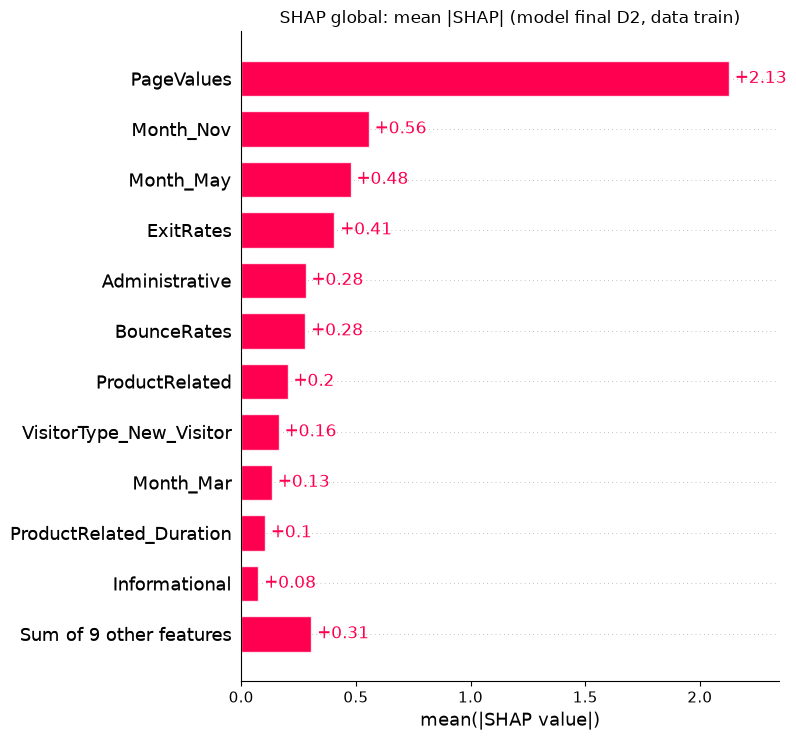

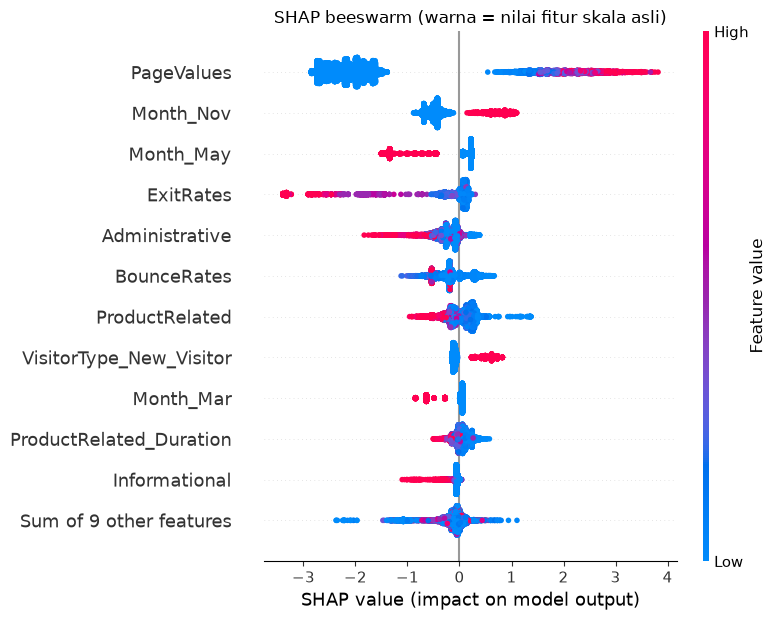

In [19]:
fig = plt.figure()
shap.plots.bar(sv_train, max_display=12, show=False)
plt.title('SHAP global: mean |SHAP| (model final D2, data train)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/tugas4_shap_bar.png', dpi=150, bbox_inches='tight'); plt.show()

fig = plt.figure()
shap.plots.beeswarm(sv_train, max_display=12, show=False)
plt.title('SHAP beeswarm (warna = nilai fitur skala asli)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/tugas4_shap_beeswarm.png', dpi=150, bbox_inches='tight'); plt.show()

In [20]:
# Stabilitas ranking global: SHAP out-of-fold (model per fold D2, dijelaskan di fold validasinya)
fold_imp = []
for k, (tr, te) in enumerate(splits_d2, start=1):
    p_k = build_pipeline(xgb, use_smote=True).fit(X.iloc[tr], y.iloc[tr])
    cols_k = p_k.named_steps['prep'].selected_cols_
    sv_k = shap.TreeExplainer(p_k.named_steps['clf'])(pd.DataFrame(p_k.named_steps['prep'].transform(X.iloc[te]), columns=cols_k))
    fold_imp.append(pd.Series(np.abs(sv_k.values).mean(0), index=cols_k, name=f'Fold {k}'))
fold_imp = pd.concat(fold_imp, axis=1)
fold_rank = fold_imp.rank(ascending=False)
stab = pd.DataFrame({'final mean|SHAP|': global_imp.round(4),
                     'OOF mean|SHAP| (rata-rata fold)': fold_imp.mean(axis=1).round(4),
                     'rank per fold (min-max)': fold_rank.min(axis=1).astype('Int64').astype(str) + '-' + fold_rank.max(axis=1).astype('Int64').astype(str),
                     'dipilih di n fold': fold_imp.notna().sum(axis=1)}).sort_values('final mean|SHAP|', ascending=False)
stab.to_csv(f'{TABLE_DIR}/tugas4_shap_stability.csv')
stab.head(12)

,final mean|SHAP|,OOF mean|SHAP| (rata-rata fold),rank per fold (min-max),dipilih di n fold
PageValues,2.1271,2.1375,1-1,5
Month_Nov,0.5568,0.4720,2-4,5
Month_May,0.4777,0.4518,2-4,5
ExitRates,0.4067,0.4163,3-4,5
Administrative,0.2813,0.2472,5-7,5
BounceRates,0.2800,0.2200,6-8,5
ProductRelated,0.2027,0.1694,7-11,5
VisitorType_New_Visitor,0.1641,0.1295,8-15,5
Month_Mar,0.1346,0.1903,6-9,5
ProductRelated_Duration,0.1043,0.0886,9-14,5


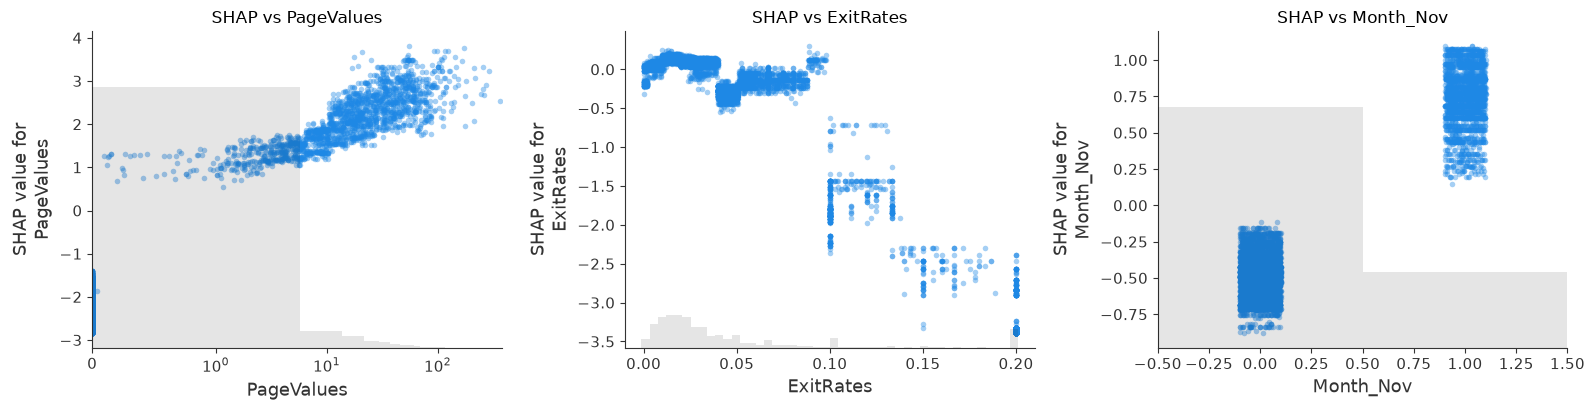

Rata-rata SHAP PageValues | PageValues = 0 : -2.146 | PageValues > 0 : 2.059
Rentang SHAP fitur lain selain PageValues (sum, persentil 5-95): [-4.608  1.073]


In [21]:
# Dependence plot fitur teratas
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, f in zip(axes, ['PageValues', 'ExitRates', 'Month_Nov']):
    shap.plots.scatter(sv_train[:, f], ax=ax, show=False, alpha=0.4)
    ax.set_title(f'SHAP vs {f}')
axes[0].set_xscale('symlog', linthresh=1); axes[0].set_xlim(left=0)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/tugas4_shap_dependence.png', dpi=150, bbox_inches='tight'); plt.show()

pv = raw_selected(X)['PageValues']
print('Rata-rata SHAP PageValues | PageValues = 0 :', sv_train[:, 'PageValues'].values[pv == 0].mean().round(3),
      '| PageValues > 0 :', sv_train[:, 'PageValues'].values[pv > 0].mean().round(3))
print('Rentang SHAP fitur lain selain PageValues (sum, persentil 5-95):',
      np.percentile(sv_train.values.sum(1) - sv_train[:, 'PageValues'].values, [5, 95]).round(3))

### Interpretasi lokal

Kasus dipilih dari prediksi **out-of-fold** D2, dan setiap kasus dijelaskan oleh **model fold yang tidak pernah
melihat baris itu**. Dengan begitu penjelasan lokal sesuai dengan prediksi yang benar-benar dievaluasi, bukan
prediksi in-sample model final.

Kasus: satu TP dan satu TN tipikal (probabilitas mendekati median kelompoknya), FP paling yakin, dan FN paling yakin.
FN paling yakin sekaligus observasi Cleanlab yang diputuskan **Keep**.

In [22]:
fold_of = np.empty(len(X), dtype=int)
for k, (_, te) in enumerate(splits_d2):
    fold_of[te] = k
fold_models = {}
def fold_model(k):
    if k not in fold_models:
        tr, _ = splits_d2[k]
        fold_models[k] = build_pipeline(xgb, use_smote=True).fit(X.iloc[tr], y.iloc[tr])
    return fold_models[k]

oof_p_d2 = np.empty(len(X))
for k, (_, te) in enumerate(splits_d2):
    oof_p_d2[te] = fold_model(k).predict_proba(X.iloc[te])[:, 1]
oof_pred = (oof_p_d2 >= 0.5).astype(int)

def pick_median(mask):
    idx = np.where(mask)[0]
    return int(idx[np.argmin(np.abs(oof_p_d2[idx] - np.median(oof_p_d2[idx])))])

cases = {
    'TP tipikal': pick_median((yv == 1) & (oof_pred == 1)),
    'TN tipikal': pick_median((yv == 0) & (oof_pred == 0)),
    'FP paling yakin': int(np.where((yv == 0) & (oof_pred == 1))[0][np.argmax(oof_p_d2[(yv == 0) & (oof_pred == 1)])]),
    'FN paling yakin': int(np.setdiff1d(np.where((yv == 1) & (oof_pred == 0))[0], REMOVE_IDX)[
        np.argmin(oof_p_d2[np.setdiff1d(np.where((yv == 1) & (oof_pred == 0))[0], REMOVE_IDX)])]),
}
def local_shap(i):
    pipe_k = fold_model(fold_of[i]); prep_k = pipe_k.named_steps['prep']
    xt = pd.DataFrame(prep_k.transform(X.iloc[[i]]), columns=prep_k.selected_cols_)
    e = shap.TreeExplainer(pipe_k.named_steps['clf'])(xt)[0]
    e.data = prep_k._encode(X.iloc[[i]])[prep_k.selected_cols_].values[0]
    e.feature_names = prep_k.selected_cols_
    return e

local_rows = []
for name, i in cases.items():
    e = local_shap(i)
    top = pd.Series(e.values, index=e.feature_names).sort_values(key=abs, ascending=False).head(3)
    local_rows.append({'Kasus': name, 'train_idx': i, 'Label': int(yv[i]), 'OOF P(beli)': round(oof_p_d2[i], 3),
                       'Cleanlab': review_table.set_index(review_table.Observation.str.extract(r'idx (\d+)')[0].astype(int))
                                   ['Decision'].get(i, '-'),
                       'Top-3 SHAP': '; '.join(f'{f}={e.data[e.feature_names.index(f)]:.3g} ({v:+.2f})' for f, v in top.items())})
local_table = pd.DataFrame(local_rows)
local_table.to_csv(f'{TABLE_DIR}/tugas4_shap_local_cases.csv', index=False)
local_table

,Kasus,train_idx,Label,OOF P(beli),Cleanlab,Top-3 SHAP
0,TP tipikal,1800,1,0.859,-,PageValues=1.96 (+1.28); Month_Nov=1 (+0.54); ...
1,TN tipikal,91,0,0.027,-,PageValues=0 (-1.95); Administrative=14 (-0.77...
2,FP paling yakin,8390,0,0.961,-,PageValues=69.7 (+2.63); Administrative=1 (-0....
3,FN paling yakin,5335,1,0.006,Keep,PageValues=0 (-1.88); Administrative=17 (-1.21...


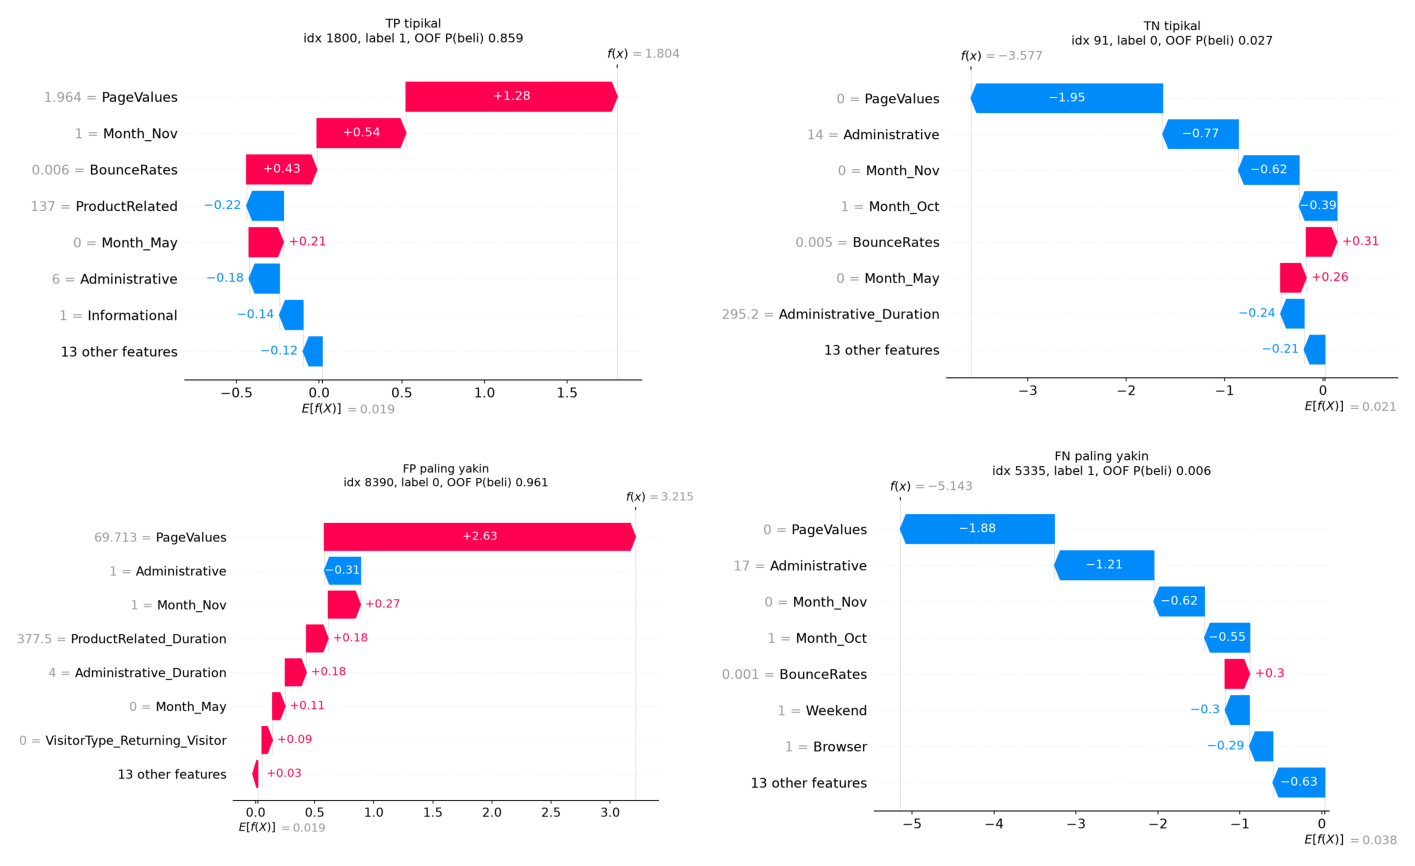

Catatan: base value E[f(X)] sedikit berbeda antar panel karena tiap kasus dijelaskan oleh model fold masing-masing.


In [23]:
# waterfall dirender per kasus (shap.plots.waterfall tidak cocok dimasukkan ke subplot), lalu digabung 2x2
wf_paths = []
for name, i in cases.items():
    plt.figure(figsize=(9, 5.5))
    shap.plots.waterfall(local_shap(i), max_display=8, show=False)
    plt.title(f'{name}\nidx {i}, label {yv[i]}, OOF P(beli) {oof_p_d2[i]:.3f}', fontsize=12)
    path = f"{FIG_DIR}/tugas4_shap_waterfall_{name.split()[0].lower()}_{i}.png"
    plt.savefig(path, dpi=150, bbox_inches='tight'); plt.close()
    wf_paths.append(path)

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, path in zip(axes.ravel(), wf_paths):
    ax.imshow(plt.imread(path)); ax.axis('off')
plt.subplots_adjust(wspace=0.02, hspace=0.04)
plt.savefig(f'{FIG_DIR}/tugas4_shap_waterfall_cases.png', dpi=150, bbox_inches='tight'); plt.show()
print('Catatan: base value E[f(X)] sedikit berbeda antar panel karena tiap kasus dijelaskan oleh model fold masing-masing.')

### LIME sebagai pembanding

LIME memakai model fold yang sama, bekerja di ruang fitur setelah preprocessing (20 fitur, data latih fold sebagai
distribusi perturbasi). Hasilnya dibandingkan dengan SHAP untuk FP dan FN, karena di dua kasus inilah penjelasan
paling dibutuhkan. `random_state` dikunci supaya reproducible.

FP paling yakin (idx 8390): kuartil PageValues (ter-standardisasi) di fold train = [-0.318 -0.318 -0.318]
FN paling yakin (idx 5335): kuartil PageValues (ter-standardisasi) di fold train = [-0.319 -0.319 -0.319]


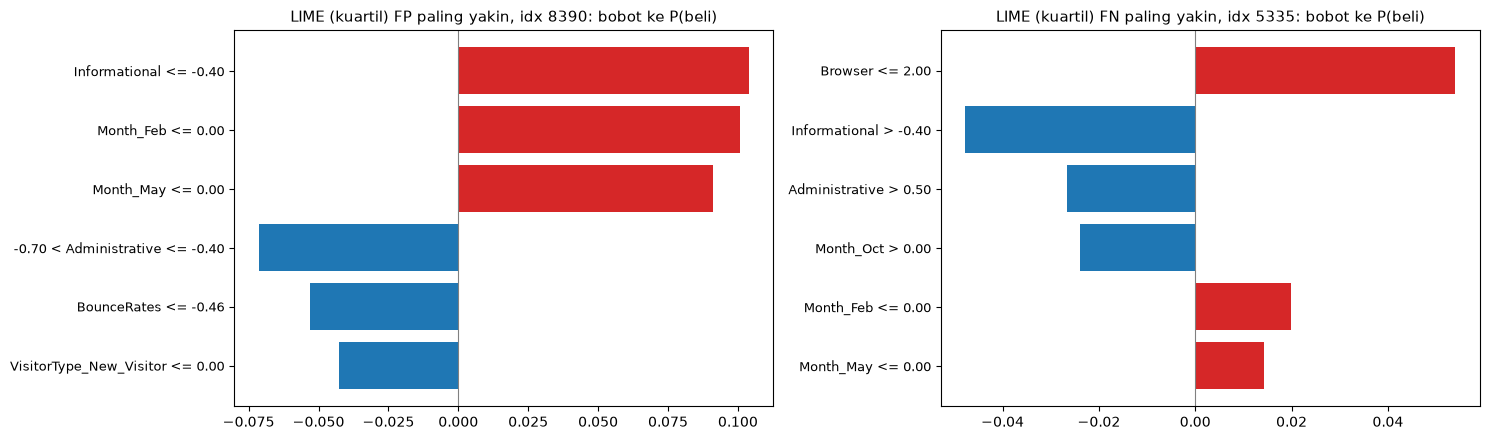

,Kasus,train_idx,Diskretisasi LIME,LIME top-3,Peringkat PageValues di LIME,Peringkat PageValues di SHAP,R2 surrogate lokal
0,FP paling yakin,8390,kuartil (default),Informational <= -0.40 (+0.104) | Month_Feb <=...,13,1,0.280
1,FP paling yakin,8390,desil,Informational <= -0.40 (+0.197) | Month_Feb <=...,19,1,0.362
2,FP paling yakin,8390,tanpa diskretisasi,PageValues (+0.048) | Month_Nov (+0.020) | Pro...,1,1,0.224
3,FN paling yakin,5335,kuartil (default),Browser <= 2.00 (+0.054) | Informational > -0....,17,1,0.274
4,FN paling yakin,5335,desil,-0.40 < Informational <= 0.38 (-0.217) | Month...,14,1,0.249
5,FN paling yakin,5335,tanpa diskretisasi,PageValues (+0.023) | Administrative (-0.023) ...,1,1,0.179


In [24]:
from lime.lime_tabular import LimeTabularExplainer
from pipeline_experiments import RANDOM_STATE

LIME_VARIANTS = {'kuartil (default)': dict(discretize_continuous=True),
                 'desil': dict(discretize_continuous=True, discretizer='decile'),
                 'tanpa diskretisasi': dict(discretize_continuous=False)}
lime_rows, lime_plot = [], {}
for name in ['FP paling yakin', 'FN paling yakin']:
    i = cases[name]; k = fold_of[i]; pipe_k = fold_model(k); prep_k = pipe_k.named_steps['prep']
    tr, _ = splits_d2[k]
    Xtr_k = prep_k.transform(X.iloc[tr]); cols_k = prep_k.selected_cols_
    x_i = prep_k.transform(X.iloc[[i]])[0]
    pv_q = np.percentile(Xtr_k[:, cols_k.index('PageValues')], [25, 50, 75])
    shap_rank = pd.Series(local_shap(i).values, index=cols_k).abs().rank(ascending=False)
    for vname, kw in LIME_VARIANTS.items():
        ex = LimeTabularExplainer(Xtr_k, feature_names=cols_k, class_names=['Tidak beli', 'Beli'],
                                  mode='classification', random_state=RANDOM_STATE, **kw
                                  ).explain_instance(x_i, pipe_k.named_steps['clf'].predict_proba,
                                                     num_features=len(cols_k), num_samples=5000)
        lst = ex.as_list()
        pv_rank = 1 + [j for j, (r, _) in enumerate(lst) if 'PageValues' in r][0]
        lime_rows.append({'Kasus': name, 'train_idx': i, 'Diskretisasi LIME': vname,
                          'LIME top-3': ' | '.join(f'{r} ({w:+.3f})' for r, w in lst[:3]),
                          'Peringkat PageValues di LIME': pv_rank,
                          'Peringkat PageValues di SHAP': int(shap_rank['PageValues']),
                          'R2 surrogate lokal': round(ex.score, 3)})
        if vname == 'kuartil (default)':
            lime_plot[name] = lst[:6]
    print(f'{name} (idx {i}): kuartil PageValues (ter-standardisasi) di fold train = {pv_q.round(3)}')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (name, lst) in zip(axes, lime_plot.items()):
    rules, vals = zip(*lst)
    ax.barh(range(len(vals))[::-1], vals, color=['tab:red' if v > 0 else 'tab:blue' for v in vals])
    ax.set_yticks(range(len(vals))[::-1]); ax.set_yticklabels(rules, fontsize=9); ax.axvline(0, color='grey', lw=0.8)
    ax.set_title(f'LIME (kuartil) {name}, idx {cases[name]}: bobot ke P(beli)', fontsize=11)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/tugas4_lime_fp_fn.png', dpi=150, bbox_inches='tight'); plt.show()

lime_table = pd.DataFrame(lime_rows)
lime_table.to_csv(f'{TABLE_DIR}/tugas4_lime_vs_shap.csv', index=False)
lime_table

### Interpretasi Step 6

**Global.**
- **PageValues mendominasi**: 41,6% dari total mean |SHAP|, peringkat 1 di kelima fold. Efeknya hampir biner:
  PageValues = 0 memberi rata-rata -2,15 log-odds, PageValues > 0 memberi +2,06, sehingga lompatan zero/non-zero
  sekitar 4 log-odds. Di atas nol efeknya naik monoton dan mendatar setelah sekitar 100. Polanya konsisten dengan EDA
  (korelasi 0,49; rate beli 57% vs 3,7%).
- **Month_Nov (+) dan Month_May (-) berada di peringkat 2 dan 3**, di atas semua fitur perilaku selain PageValues.
  Konsisten dengan EDA (November musim belanja akhir tahun; Mei punya banyak sesi tetapi konversinya rendah). Ini
  efek musiman, bukan perilaku sesi, dan data hanya mencakup satu tahun (Januari dan April tidak ada), jadi efek
  bulan berisiko tidak tergeneralisasi ke tahun lain.
- **ExitRates** negatif kuat hanya di atas sekitar 0,10 (sesi pendek). **BounceRates** dan ExitRates berkorelasi
  0,91, sehingga atribusinya terbagi di antara keduanya.
- **Perilaku tak terduga**: Administrative dan ProductRelated yang tinggi justru mendapat SHAP **negatif**, padahal di
  EDA keduanya berkorelasi positif dengan pembelian. Dugaannya: setelah PageValues menangkap sebagian besar sinyal
  pembelian, jumlah halaman yang tinggi *tanpa* PageValues menandakan penjelajahan tanpa tujuan. Ini dicek di Step 7.
- `VisitorType_Returning_Visitor` mendapat SHAP 0. Informasinya sudah terwakili oleh `VisitorType_New_Visitor`.

**Lokal (model fold yang tidak melihat barisnya).**
- **TP dan TN tipikal** dijelaskan terutama oleh PageValues (+1,28 dan -1,95). Bulan dan jumlah halaman administratif
  menjadi faktor kedua.
- **FP paling yakin (idx 8390, P = 0,961)**: PageValues 69,7 di bulan November. Model hampir hanya melihat PageValues.
  Sesi ini mengunjungi halaman bernilai tinggi tetapi tidak membeli. Labelnya masuk akal (orang bisa meninggalkan
  keranjang), jadi kesalahan ini batas informasi fitur, bukan label salah.
- **FN paling yakin (idx 5335, P = 0,006)** adalah observasi Cleanlab yang diputuskan **Keep**: 17 halaman
  administratif dan 83 halaman produk, tetapi PageValues = 0. PageValues (-1,88) dan Administrative tinggi (-1,21)
  menekan prediksi. SHAP menegaskan dugaan Step 4: flag Cleanlab di observasi ini berasal dari ketergantungan model
  pada PageValues, bukan bukti bahwa labelnya salah.

**LIME baru sejalan dengan SHAP setelah diskretisasi dimatikan, dan penyebabnya teknis.** 78% nilai PageValues
adalah 0, sehingga kuartil Q1, Q2, dan Q3 di data train sama persis. Diskretisasi kuartil (default) dan desil LIME
runtuh untuk fitur ini, dan PageValues tenggelam ke peringkat 13 sampai 19, padahal SHAP menempatkannya di peringkat 1
untuk kedua kasus. Tanpa diskretisasi, LIME juga menempatkan PageValues di peringkat 1. Namun R² surrogate linear
lokal hanya 0,18 sampai 0,36 di semua varian, jadi model linear lokal tidak bisa meniru fungsi tangga XGBoost di
sekitar lompatan PageValues. Karena TreeExplainer menghitung SHAP secara eksak untuk model pohon (aditivitas
terverifikasi, error maksimum sekitar 1e-5), **interpretasi utama memakai SHAP**. LIME dilaporkan sebagai pembanding
beserta keterbatasannya.

## 7. Menghubungkan Interpretasi Model dengan Kualitas Data

Empat pertanyaan dari Step 6 diinvestigasi di data train (prediksi out-of-fold D2):

1. Kenapa Administrative dan ProductRelated yang tinggi mendapat SHAP negatif?
2. Apakah ketergantungan pada PageValues menandakan leakage?
3. Dari mana sumber kesalahan prediksi: data, label, fitur, atau model?
4. Apakah duplikat menggelembungkan skor CV?

In [25]:
# 7.1 Administrative / ProductRelated: rate beli per kuartil, dipisah PageValues = 0 vs > 0
d['PV>0'] = d.PageValues > 0
cond_tables = {}
for f in ['Administrative', 'ProductRelated']:
    t = d.assign(bin=pd.qcut(d[f], 4, duplicates='drop')).pivot_table(
        index='bin', columns='PV>0', values='Revenue', aggfunc=['mean', 'size'], observed=True)
    t.columns = [f'{"rate beli" if a == "mean" else "n"} (PV>0={b})' for a, b in t.columns]
    cond_tables[f] = t
    print(f'\n{f}:'); print(t.round(3))
pd.concat(cond_tables).to_csv(f'{TABLE_DIR}/tugas4_pages_vs_revenue_by_pv.csv')

S = pd.DataFrame(sv_train.values, columns=FEATS)
for f, thr in [('Administrative', 5), ('ProductRelated', 50)]:
    hi = (d[f] > thr).values; pvp = d['PV>0'].values
    print(f'{f} > {thr}: rata-rata SHAP {S[f][hi & ~pvp].mean():+.3f} (PV=0) vs {S[f][hi & pvp].mean():+.3f} (PV>0) '
          f'| <= {thr}: {S[f][~hi & ~pvp].mean():+.3f} vs {S[f][~hi & pvp].mean():+.3f}')

iv = explainer.shap_interaction_values(Xt_train)
a_i, p_i = FEATS.index('Administrative'), FEATS.index('PageValues')
print(f'Mean |efek utama Administrative| {np.abs(iv[:, a_i, a_i]).mean():.4f} vs '
      f'mean |interaksi Administrative x PageValues| {np.abs(iv[:, a_i, p_i]).mean():.4f}')


Administrative:
               rate beli (PV>0=False)  rate beli (PV>0=True)  n (PV>0=False)  n (PV>0=True)
bin                                                                                        
(-0.001, 1.0]                   0.026                  0.747            4375            594
(1.0, 4.0]                      0.050                  0.583            1452            515
(4.0, 27.0]                     0.067                  0.431             893            802

ProductRelated:
               rate beli (PV>0=False)  rate beli (PV>0=True)  n (PV>0=False)  n (PV>0=True)
bin                                                                                        
(-0.001, 7.0]                   0.022                  0.794            2148             68
(7.0, 18.0]                     0.026                  0.794            1880            339
(18.0, 37.0]                    0.035                  0.602            1453            591
(37.0, 705.0]                   0.080         

Mean |efek utama Administrative| 0.2557 vs mean |interaksi Administrative x PageValues| 0.0806


In [26]:
# 7.2 Sensitivitas PageValues (diagnosis saja, model final tidak diubah)
summ_nopv, _ = cv_evaluate(build_pipeline(xgb, use_smote=True, drop_features=['PageValues']), X, y, cv=splits_d2)
pv_sens = pd.DataFrame({'D2 (dengan PageValues)': summary_d2.loc[['MCC', 'Macro F1', 'auPR', 'auROC'], 'Mean'],
                        'D2 tanpa PageValues': summ_nopv.loc[['MCC', 'Macro F1', 'auPR', 'auROC'], 'Mean']})
pv_sens.to_csv(f'{TABLE_DIR}/tugas4_pagevalues_sensitivity.csv')
buyers = d[d.Revenue == 1]
print(f'Pembeli dengan PageValues = 0: {(buyers.PageValues == 0).sum()} dari {len(buyers)} '
      f'({(buyers.PageValues == 0).mean():.1%})')
pv_sens

Pembeli dengan PageValues = 0: 246 dari 1336 (18.4%)


,D2 (dengan PageValues),D2 tanpa PageValues
MCC,0.6195,0.2588
Macro F1,0.8079,0.6275
auPR,0.7321,0.3389
auROC,0.9267,0.7583


In [27]:
# 7.3 Analisis kesalahan prediksi OOF (threshold 0,5)
d['oof'] = oof_p_d2; d['pred'] = oof_pred
d['err'] = np.select([(yv == 1) & (oof_pred == 0), (yv == 0) & (oof_pred == 1)], ['FN', 'FP'], 'OK')
errs = d.err != 'OK'
print('Jumlah:', d.err.value_counts().to_dict())
print(f"FN dengan PageValues = 0: {(d[d.err == 'FN'].PageValues == 0).mean():.1%} | "
      f"FP dengan PageValues > 0: {(d[d.err == 'FP'].PageValues > 0).mean():.1%}")
print(f'Kesalahan dekat threshold (P 0,35-0,65): {(errs & d.oof.between(0.35, 0.65)).sum()} dari {errs.sum()} | '
      f'kesalahan sangat yakin (P < 0,1 atau > 0,9): {(errs & ((d.oof < 0.1) | (d.oof > 0.9))).sum()}')

prof_cols7 = ['Administrative', 'ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'PageValues']
profile = pd.concat({
    'FN (PV=0)': d[(d.err == 'FN') & ~d['PV>0']][prof_cols7].median(),
    'TN (PV=0)': d[(d.err == 'OK') & (yv == 0) & ~d['PV>0']][prof_cols7].median(),
    'TP': d[(d.err == 'OK') & (yv == 1)][prof_cols7].median(),
    'FP': d[d.err == 'FP'][prof_cols7].median(),
}, axis=1).round(3)
profile.to_csv(f'{TABLE_DIR}/tugas4_error_profiles.csv')
print('\nProfil median per kelompok:'); print(profile)

seg = d.groupby('Month').agg(n=('Revenue', 'size'), rate_beli=('Revenue', 'mean'),
                             FN=('err', lambda s: (s == 'FN').sum()), FP=('err', lambda s: (s == 'FP').sum()))
seg['error_rate'] = (seg.FN + seg.FP) / seg.n
seg = seg.sort_values('error_rate', ascending=False).round(3)
seg.to_csv(f'{TABLE_DIR}/tugas4_error_by_month.csv')
print(f"\nKorelasi error rate vs rate beli antar bulan: {seg.error_rate.corr(seg.rate_beli):.2f}")
vc = d.TrafficType.value_counts(); rare = d.TrafficType.isin(vc[vc < 30].index)
print(f'Error rate TrafficType langka: {errs[rare].mean():.3f} (n={rare.sum()}) vs lainnya {errs[~rare].mean():.3f}')
for v in ['New_Visitor', 'Returning_Visitor', 'Other']:
    m = d.VisitorType == v
    print(f'Error rate {v}: {errs[m].mean():.3f} (n={m.sum()})')
seg

Jumlah: {'OK': 7702, 'FP': 583, 'FN': 346}
FN dengan PageValues = 0: 69.7% | FP dengan PageValues > 0: 97.1%
Kesalahan dekat threshold (P 0,35-0,65): 269 dari 929 | kesalahan sangat yakin (P < 0,1 atau > 0,9): 133

Profil median per kelompok:
                         FN (PV=0)  TN (PV=0)        TP        FP
Administrative               2.000      0.000     2.000     4.000
ProductRelated              27.000     13.000    27.000    39.000
ProductRelated_Duration    916.922    409.750  1081.812  1543.423
ExitRates                    0.023      0.031     0.014     0.019
PageValues                   0.000      0.000    26.255    14.385

Korelasi error rate vs rate beli antar bulan: 0.95
Error rate TrafficType langka: 0.063 (n=63) vs lainnya 0.108
Error rate New_Visitor: 0.087 (n=1190)
Error rate Returning_Visitor: 0.111 (n=7374)
Error rate Other: 0.060 (n=67)


,n,rate_beli,FN,FP,error_rate
Month,,,,,
Sep,319,0.197,23,31,0.169
Nov,2066,0.253,157,192,0.169
Oct,381,0.218,25,31,0.147
Aug,308,0.185,17,28,0.146
Jul,299,0.134,15,24,0.130
Dec,1208,0.132,43,82,0.103
June,189,0.101,6,8,0.074
May,2377,0.106,42,118,0.067
Mar,1351,0.103,17,69,0.064


In [28]:
# 7.4 Duplikat: fold sama, validasi diulang tanpa baris yang punya kembaran identik di fold train
from sklearn.metrics import matthews_corrcoef
row_key = pd.util.hash_pandas_object(X[feat], index=False).values
n_cross, mcc_all, mcc_masked = 0, [], []
for tr, te in splits_d2:
    cross = np.isin(row_key[te], row_key[tr])
    n_cross += cross.sum()
    mcc_all.append(matthews_corrcoef(yv[te], oof_pred[te]))
    mcc_masked.append(matthews_corrcoef(yv[te][~cross], oof_pred[te][~cross]))
dup_rows = d.duplicated(subset=feat, keep=False)
print(f'Baris validasi yang kembarannya ada di fold train: {n_cross}')
print(f'MCC CV semua baris {np.mean(mcc_all):.4f} vs tanpa baris kembar {np.mean(mcc_masked):.4f}')
print('Hasil prediksi baris duplikat:', d.loc[dup_rows, 'err'].value_counts().to_dict())

Baris validasi yang kembarannya ada di fold train: 106
MCC CV semua baris 0.6195 vs tanpa baris kembar 0.6185
Hasil prediksi baris duplikat: {'OK': 126}


### Interpretasi Step 7

**7.1 Administrative dan ProductRelated negatif adalah hubungan yang nyata di data, bukan error.**
Korelasi positifnya di EDA bersifat marginal. Begitu dipisah berdasarkan PageValues, polanya terbalik: di antara sesi
dengan PageValues > 0, rate beli turun seiring jumlah halaman (Administrative 74,7% ke 43,1%; ProductRelated 79,4% ke
45,0%). Sesi yang mencapai halaman bernilai lalu terus menjelajah lebih jarang menyelesaikan transaksi. Korelasi
marginal yang positif muncul karena sesi panjang lebih sering punya PageValues > 0. SHAP mengikuti pola ini (paling
negatif saat Administrative > 5 dan PageValues > 0), dan sebagian besar berupa efek utama (0,26) dibanding interaksi
dengan PageValues (0,08). Tidak ada koreksi data yang dibutuhkan.

**7.2 PageValues: dominan dan berisiko leakage parsial, tetapi tidak dihapus.** Tanpa PageValues, MCC CV turun dari
0,6195 ke 0,2588 dan auPR dari 0,73 ke 0,34, jadi hampir separuh kemampuan model bergantung pada satu fitur. Menurut
dokumentasi UCI, PageValues adalah nilai rata-rata halaman yang dikunjungi sebelum transaksi, metrik Google Analytics
yang dihitung dari transaksi di seluruh situs. Kalau periode perhitungannya mencakup sesi itu sendiri, transaksi sesi
tersebut ikut membentuk nilai fiturnya (target-derived aggregate). Ini tidak bisa diverifikasi dari data yang tersedia.
Fitur ini juga tidak deterministik: 18,4% pembeli punya PageValues = 0 dan 43% sesi dengan PageValues > 0 tidak membeli.
Keputusan: PageValues **dipertahankan** supaya model tetap konsisten dengan baseline, dan risikonya dilaporkan sebagai
limitasi. Untuk penerapan nyata, PageValues harus dihitung dari periode historis sebelum sesi.

**7.3 Sumber kesalahan prediksi.**

| Kelompok | Bukti | Sumber utama |
|---|---|---|
| FN (346) | 69,7% punya PageValues = 0. Profilnya (27 hal. produk, 917 dtk) mirip TP (27 hal., 1.082 dtk), jauh dari TN (13 hal., 410 dtk) | **Fitur/data**: perilaku menyerupai pembeli, tetapi PageValues yang bernilai 0 tidak memberi sinyal. Label tidak terbukti salah (review Cleanlab: 0 koreksi) |
| FP (583) | 97,1% punya PageValues > 0, tetapi lebih rendah dari TP (14,4 vs 26,3) dengan halaman lebih banyak (39 vs 27) | **Fitur**: sesi yang mencapai halaman bernilai lalu tidak membeli (mirip keranjang ditinggalkan). Informasi keranjang/checkout tidak ada di dataset |
| Dekat threshold (269 dari 929) | P(beli) 0,35 sampai 0,65 | **Model/threshold**: kasus ambigu, sensitif terhadap pilihan threshold 0,5 dan noise SMOTE |
| Sangat yakin (133) | P < 0,1 atau > 0,9 | Dua di antaranya record bounce murni yang sudah dibuang dari training; sisanya kasus seperti FN/FP di atas |

Error rate antar bulan berkorelasi 0,95 dengan rate beli: kesalahan menumpuk di bulan dengan banyak pembeli (Sep, Nov,
Oct, Aug), bukan di segmen data yang rusak. Kategori TrafficType langka tidak bermasalah (error 6,3% vs 10,8%), jadi
temuan (f) di Step 2 tidak perlu ditindaklanjuti.

**7.4 Duplikat tidak menggelembungkan skor CV.** 106 baris validasi punya kembaran identik di fold train. Tanpa baris
itu, MCC 0,6185 vs 0,6195. Ke-126 baris duplikat semuanya diprediksi benar karena merupakan sesi bounce yang mudah,
jadi keputusan Step 2 untuk tidak menghapusnya tetap berlaku.

**Koreksi data tambahan dari Step 7: tidak ada.** Hitungan seluruh dataset menunjukkan pola bounce murni dengan
Revenue = 1 hanya muncul 3 kali: 2 di train (sudah dibuang di D2) dan 1 di test (idx 264). Record test tidak diubah,
dan kemungkinan besar akan menjadi false negative di evaluasi akhir.